In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader

# Read the uploaded Kaggle CSV file
file_path = "Shakespeare_data.csv"
print(f"Loading local dataset from {file_path}...")

try:
    df = pd.read_csv(file_path)
    # The Kaggle CSV contains a column named 'PlayerLine' holding the actual dialogue text
    # We join all these lines with a newline character to create our continuous text corpus
    text = "\n".join(df['PlayerLine'].dropna().astype(str).tolist())
    print(f"Dataset length: {len(text)} characters")
except FileNotFoundError:
    print(f"ERROR: Could not find {file_path}. Please upload it to the Colab files pane first!")


Loading local dataset from Shakespeare_data.csv...
Dataset length: 4366287 characters


In [2]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(f"Vocabulary size (V): {vocab_size}")

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi.get(c, 0) for c in s] # fallback to 0 if unknown
decode = lambda l: ''.join([itos[i] for i in l])

class CharDataset(Dataset):
    def __init__(self, data, block_size):
        self.data = torch.tensor(data, dtype=torch.long)
        self.block_size = block_size

    def __len__(self):
        return (len(self.data) - 1) // self.block_size

    def __getitem__(self, idx):
        start = idx * self.block_size
        x = self.data[start : start + self.block_size]
        y = self.data[start + 1 : start + self.block_size + 1]
        return x, y

T = 128
train_size = int(0.9 * len(text))
train_data = encode(text[:train_size])
val_data = encode(text[train_size:])

train_dataset = CharDataset(train_data, T)
val_dataset = CharDataset(val_data, T)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, drop_last=True)


Vocabulary size (V): 77


In [3]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, Q, K, V, mask=None):
        d_k = Q.size(-1)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        attn_weights = F.softmax(scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_k = d_model // num_heads
        self.num_heads = num_heads

        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)
        self.attention = ScaledDotProductAttention()

    def forward(self, x, mask=None):
        B, T, D = x.size()

        Q = self.W_q(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)

        out, attn_weights = self.attention(Q, K, V, mask)

        out = out.transpose(1, 2).contiguous().view(B, T, D)
        return self.W_o(out), attn_weights

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

class TransformerBlock(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.ffn = FeedForward(d_model, d_model * 4)
        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None):
        mha_out, attn_weights = self.mha(self.ln1(x), mask)
        x = x + mha_out
        x = x + self.ffn(self.ln2(x))
        return x, attn_weights

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, mode='learned'):
        super().__init__()
        self.mode = mode
        if mode == 'learned':
            self.pe = nn.Embedding(max_len, d_model)
        elif mode == 'sinusoidal':
            pe = torch.zeros(max_len, d_model)
            position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
            div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
            pe[:, 0::2] = torch.sin(position * div_term)
            pe[:, 1::2] = torch.cos(position * div_term)
            self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        T = x.size(1)
        if self.mode == 'learned':
            positions = torch.arange(0, T, device=x.device).unsqueeze(0)
            return self.pe(positions)
        else:
            return self.pe[:, :T, :]

class GPTModel(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, num_layers, max_len, pe_mode='learned'):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = PositionalEncoding(d_model, max_len, pe_mode)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, num_heads) for _ in range(num_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.register_buffer('causal_mask', torch.tril(torch.ones(max_len, max_len)).view(1, 1, max_len, max_len))

    def forward(self, x):
        B, T = x.size()
        mask = self.causal_mask[:, :, :T, :T]

        x = self.token_emb(x) + self.pos_emb(x)

        attn_maps = []
        for block in self.blocks:
            x, attn_weights = block(x, mask)
            attn_maps.append(attn_weights)

        x = self.ln_f(x)
        logits = self.lm_head(x)
        return logits, attn_maps


In [4]:
def generate_text(model, start_str, max_new_tokens, temperature=1.0):
    model.eval()
    context = torch.tensor(encode(start_str), dtype=torch.long, device=device).unsqueeze(0)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            context_crop = context[:, -T:]
            logits, _ = model(context_crop)
            logits = logits[:, -1, :]

            if temperature == 0.0:
                idx_next = torch.argmax(logits, dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                probs = F.softmax(logits, dim=-1)
                idx_next = torch.multinomial(probs, num_samples=1)

            context = torch.cat((context, idx_next), dim=1)

    return decode(context[0].tolist())


In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

def evaluate(model, dataloader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for X, Y in dataloader:
            X, Y = X.to(device), Y.to(device)
            logits, _ = model(X)
            loss = F.cross_entropy(logits.view(-1, vocab_size), Y.view(-1))
            total_loss += loss.item()
    avg_loss = total_loss / len(dataloader)
    ppl = math.exp(avg_loss)
    return avg_loss, ppl

def train_model(model, train_loader, val_loader, epochs=15, lr=1e-3, early_stop_diff=1e-4):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    train_losses, val_losses, val_ppls = [], [], []
    prev_train_loss = float('inf')

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0

        for batch_idx, (X, Y) in enumerate(train_loader):
            X, Y = X.to(device), Y.to(device)

            optimizer.zero_grad()
            logits, _ = model(X)
            loss = F.cross_entropy(logits.view(-1, vocab_size), Y.view(-1))
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()

            if batch_idx % 100 == 0 and batch_idx > 0:
                print(f"Epoch {epoch+1} | Batch {batch_idx}/{len(train_loader)} | Loss: {loss.item():.4f}")

        avg_train_loss = total_train_loss / len(train_loader)
        avg_val_loss, val_ppl = evaluate(model, val_loader)

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        val_ppls.append(val_ppl)

        print(f"--- Epoch {epoch+1} Summary ---")
        print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val PPL: {val_ppl:.4f}")

        diff = abs(avg_train_loss - prev_train_loss)
        if diff < early_stop_diff:
            print(f"Convergence reached! |L_k - L_(k-1)| = {diff:.6f} < {early_stop_diff}")
            break

        prev_train_loss = avg_train_loss

    return train_losses, val_losses, val_ppls


Using device: cuda


Training Baseline: L=4, H=4, d_model=128, Learned Pos Encoding...
Epoch 1 | Batch 100/479 | Loss: 2.5039
Epoch 1 | Batch 200/479 | Loss: 2.3491
Epoch 1 | Batch 300/479 | Loss: 2.1800
Epoch 1 | Batch 400/479 | Loss: 2.0793
--- Epoch 1 Summary ---
Train Loss: 2.3273 | Val Loss: 1.9743 | Val PPL: 7.2014
Epoch 2 | Batch 100/479 | Loss: 1.8646
Epoch 2 | Batch 200/479 | Loss: 1.8267
Epoch 2 | Batch 300/479 | Loss: 1.8048
Epoch 2 | Batch 400/479 | Loss: 1.7334
--- Epoch 2 Summary ---
Train Loss: 1.8175 | Val Loss: 1.7174 | Val PPL: 5.5699
Epoch 3 | Batch 100/479 | Loss: 1.6527
Epoch 3 | Batch 200/479 | Loss: 1.6375
Epoch 3 | Batch 300/479 | Loss: 1.6125
Epoch 3 | Batch 400/479 | Loss: 1.6334
--- Epoch 3 Summary ---
Train Loss: 1.6412 | Val Loss: 1.6147 | Val PPL: 5.0261
Epoch 4 | Batch 100/479 | Loss: 1.5618
Epoch 4 | Batch 200/479 | Loss: 1.5583
Epoch 4 | Batch 300/479 | Loss: 1.5379
Epoch 4 | Batch 400/479 | Loss: 1.5329
--- Epoch 4 Summary ---
Train Loss: 1.5527 | Val Loss: 1.5591 | Val PP

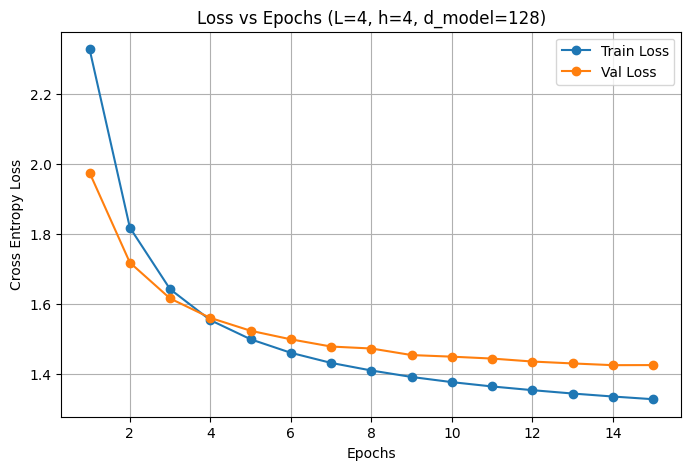

In [6]:
print("Training Baseline: L=4, H=4, d_model=128, Learned Pos Encoding...")
model = GPTModel(vocab_size=vocab_size, d_model=128, num_heads=4, num_layers=4, max_len=T, pe_mode='learned').to(device)
train_losses, val_losses, val_ppls = train_model(model, train_loader, val_loader, epochs=15)

plt.figure(figsize=(8,5))
plt.plot(range(1, len(train_losses)+1), train_losses, marker='o', label='Train Loss')
plt.plot(range(1, len(val_losses)+1), val_losses, marker='o', label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Cross Entropy Loss')
plt.title('Loss vs Epochs (L=4, h=4, d_model=128)')
plt.legend()
plt.grid()
plt.show()


In [7]:
print("\n--- Text Generation Samples ---")
prompts = ["ROMEO:\n", "KING:\n", "What light ", "To be or ", "Wherefore art "]
temperatures = [0.0, 0.5, 0.8, 1.2]

for prompt in prompts:
    for temp in temperatures:
        mode = "Greedy" if temp == 0.0 else f"Temp={temp}"
        gen = generate_text(model, prompt, max_new_tokens=50, temperature=temp)
        print(f"[{mode}] Prompt: '{prompt.strip()}' -> {gen.replace(chr(10), ' ')}")



--- Text Generation Samples ---
[Greedy] Prompt: 'ROMEO:' -> ROMEO: The thing of the court of the court, and the thing
[Temp=0.5] Prompt: 'ROMEO:' -> ROMEO: What, God and the Tower, the three of my throne. S
[Temp=0.8] Prompt: 'ROMEO:' -> ROMEO: Now be this bosom of the sexton peace of love, I w
[Temp=1.2] Prompt: 'ROMEO:' -> ROMEO: 'AGON! What, within, sir. lander? Hamlant! Dearth!
[Greedy] Prompt: 'KING:' -> KING: The same of the prince of the streets of the stree
[Temp=0.5] Prompt: 'KING:' -> KING: Why, who is the place of court, and so many That t
[Temp=0.8] Prompt: 'KING:' -> KING: My lord, will do, and try care it there not, To pa
[Temp=1.2] Prompt: 'KING:' -> KING: Arm, hence, name!--ay, Well, dame, if your woe, th
[Greedy] Prompt: 'What light' -> What light the soul of the streets of the streets. What shall
[Temp=0.5] Prompt: 'What light' -> What light to the counsel of Cassio of Time, By the gods and 
[Temp=0.8] Prompt: 'What light' -> What light that beat an advice and news?

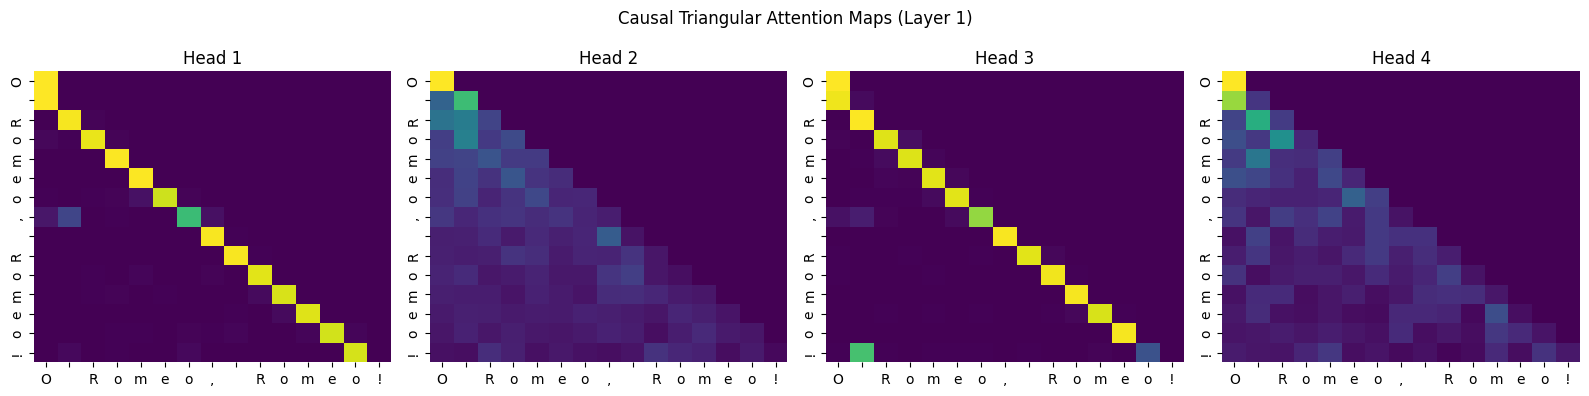

In [8]:
def plot_attention_map(model, text_str):
    model.eval()
    tokens = encode(text_str)
    x = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)

    with torch.no_grad():
        _, attn_maps = model(x)

    attn = attn_maps[0][0].cpu().numpy()
    num_heads = attn.shape[0]

    fig, axes = plt.subplots(1, num_heads, figsize=(4*num_heads, 4))
    if num_heads == 1:
        axes = [axes]

    chars_labels = [itos.get(t, '?') for t in tokens]

    for h in range(num_heads):
        sns.heatmap(attn[h], ax=axes[h], cmap='viridis', cbar=False,
                    xticklabels=chars_labels, yticklabels=chars_labels)
        axes[h].set_title(f'Head {h+1}')

    plt.suptitle("Causal Triangular Attention Maps (Layer 1)")
    plt.tight_layout()
    plt.show()

plot_attention_map(model, "O Romeo, Romeo!")
